In [198]:
from google.colab import drive

drive.mount('/content/drive2/', force_remount=True)

Mounted at /content/drive2/


In [2]:
from pathlib import Path

ds_fusion_texte_video = Path("/content/drive2/MyDrive/Projet Multimédia/Fatima ez zahra /Fusion_Texte_video")

## Prepartion et comparaison des deux modeles

In [168]:
import pandas as pd
for fichier in ds_fusion_texte_video.glob("probas_video_*.csv"):
    df = pd.read_csv(fichier)
    print(fichier.name, df.shape)

probas_video_test.csv (439, 9)
probas_video_dev.csv (442, 9)
probas_video_train.csv (2207, 9)


In [186]:
for fichier in ds_fusion_texte_video.glob("probas_text_*.csv"):
    df = pd.read_csv(fichier)
    print(fichier.name, df.shape)

probas_text_test.csv (439, 10)
probas_text_dev.csv (442, 10)
probas_text_train.csv (2207, 10)


In [170]:
for nom in [
    "probas_video_train.csv",
    "probas_text_train.csv"
]:
    df = pd.read_csv(ds_fusion_texte_video / nom)
    print("\n", nom)
    print(df.columns.tolist())
    print(df.head(2))


 probas_video_train.csv
['video_id', 'amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']
         video_id  amusement     anger       awe  contentment   disgust  \
0  00002_clip_004   0.006810  0.460118  0.040771     0.266169  0.111357   
1  00002_clip_006   0.050141  0.256813  0.070690     0.119406  0.080205   

   excitement      fear   sadness  
0    0.062161  0.025512  0.027102  
1    0.069881  0.039126  0.313738  

 probas_text_train.csv
['video_id', 'p_amusement', 'p_awe', 'p_contentment', 'p_excitement', 'p_anger', 'p_disgust', 'p_fear', 'p_sadness', 'available']
         video_id  p_amusement     p_awe  p_contentment  p_excitement  \
0  00002_clip_004     0.061735  0.088677       0.142521      0.160876   
1  00002_clip_006     0.170582  0.031327       0.139064      0.166933   

    p_anger  p_disgust    p_fear  p_sadness  available  
0  0.199290   0.094943  0.115958   0.135999          1  
1  0.099002   0.067805  0.067486   0.257801         

In [171]:
df_text_train = pd.read_csv(
    ds_fusion_texte_video / "probas_text_train.csv"
)

print(df_text_train["available"].value_counts(dropna=False))

available
1    2207
Name: count, dtype: int64


vérifier l'alignement des identifiants

In [172]:
df_video_train = pd.read_csv(ds_fusion_texte_video / "probas_video_train.csv")
df_text_train = pd.read_csv(ds_fusion_texte_video / "probas_text_train.csv")

print("Même nombre de vidéos :",len(df_video_train) == len(df_text_train))
print("Même ordre des video_id :",df_video_train["video_id"].equals(df_text_train["video_id"]))
print("Mêmes video_id :",set(df_video_train["video_id"]) == set(df_text_train["video_id"]))

Même nombre de vidéos : True
Même ordre des video_id : True
Mêmes video_id : True


In [173]:
for split in ["dev", "test"]:

    df_video = pd.read_csv(
        ds_fusion_texte_video / f"probas_video_{split}.csv"
    )

    df_text = pd.read_csv(
        ds_fusion_texte_video / f"probas_text_{split}.csv"
    )

    print(f"\n{split.upper()}")
    print("Même nombre :", len(df_video) == len(df_text))
    print("Même ordre :", df_video["video_id"].equals(df_text["video_id"]))
    print("Mêmes IDs :", set(df_video["video_id"]) == set(df_text["video_id"]))


DEV
Même nombre : True
Même ordre : True
Mêmes IDs : True

TEST
Même nombre : True
Même ordre : True
Mêmes IDs : True


In [174]:
classes_emotions = [
    "amusement",
    "anger",
    "awe",
    "contentment",
    "disgust",
    "excitement",
    "fear",
    "sadness"
]

def preparer_donnees_fusion(df_video, df_texte):

    video_ids = df_video["video_id"].values
    probabilites_video = df_video[classes_emotions].values
    probabilites_texte = df_texte[
        [f"p_{emotion}" for emotion in classes_emotions]
    ].values

    return video_ids, probabilites_texte, probabilites_video

Préparer les données Train, Dev et Test

In [175]:
# Train
video_train = pd.read_csv(ds_fusion_texte_video / "probas_video_train.csv")
texte_train = pd.read_csv(ds_fusion_texte_video / "probas_text_train.csv")

video_ids_train, probabilites_texte_train, probabilites_video_train = preparer_donnees_fusion(video_train, texte_train)

# Dev
video_dev = pd.read_csv(ds_fusion_texte_video / "probas_video_dev.csv")
texte_dev = pd.read_csv(ds_fusion_texte_video / "probas_text_dev.csv")

video_ids_dev, probabilites_texte_dev, probabilites_video_dev = preparer_donnees_fusion(video_dev, texte_dev)

# Test
video_test = pd.read_csv(ds_fusion_texte_video / "probas_video_test.csv")
texte_test = pd.read_csv(ds_fusion_texte_video / "probas_text_test.csv")

video_ids_test, probabilites_texte_test, probabilites_video_test = preparer_donnees_fusion(video_test, texte_test)

Verfier la dimension

In [176]:
print("Probabilités texte train :", probabilites_texte_train.shape)
print("Probabilités vidéo train :", probabilites_video_train.shape)

print("Probabilités texte dev :", probabilites_texte_dev.shape)
print("Probabilités vidéo dev :", probabilites_video_dev.shape)

print("Probabilités texte test :", probabilites_texte_test.shape)
print("Probabilités vidéo test :", probabilites_video_test.shape)

Probabilités texte train : (2207, 8)
Probabilités vidéo train : (2207, 8)
Probabilités texte dev : (442, 8)
Probabilités vidéo dev : (442, 8)
Probabilités texte test : (439, 8)
Probabilités vidéo test : (439, 8)


In [177]:
import numpy as np
# Charger les étiquettes des vidéos
labels_partitions = pd.read_csv(
    ds_fusion_texte_video / "labels_partitions.csv",
    dtype=str
)

# Récupérer les étiquettes de l'ensemble Dev
labels_dev = labels_partitions[
    labels_partitions["split"] == "dev"
].copy()
labels_train = labels_partitions[
    labels_partitions["split"] == "train"
].copy()

# Vérifier que les identifiants sont dans le même ordre
assert np.array_equal(
    video_ids_dev,
    labels_dev["video_id"].values
)

# Récupérer les émotions réelles
emotions_reelles_dev = labels_dev["emotion"].values
emotions_reelles_train = labels_dev["emotion"].values

print("Nombre d'étiquettes Dev :", len(emotions_reelles_dev))
print("Nombre de vidéos Dev :", len(video_ids_dev))
print("Identifiants correctement alignés :", True)

Nombre d'étiquettes Dev : 442
Nombre de vidéos Dev : 442
Identifiants correctement alignés : True


In [178]:
# Récupérer les étiquettes de Test
labels_test = labels_partitions[
    labels_partitions["split"] == "test"
].copy()

# Vérifier l'alignement des identifiants
assert np.array_equal(
    video_ids_test,
    labels_test["video_id"].values
)

# Récupérer les émotions réelles
emotions_reelles_test = labels_test["emotion"].values

# Normaliser les probabilités
probabilites_texte_test = (
    probabilites_texte_test /
    probabilites_texte_test.sum(axis=1, keepdims=True)
)

probabilites_video_test = (
    probabilites_video_test /
    probabilites_video_test.sum(axis=1, keepdims=True)
)

print("Nombre d'étiquettes Test :", len(emotions_reelles_test))
print("Nombre de vidéos Test :", len(video_ids_test))
print("Identifiants correctement alignés :", True)

Nombre d'étiquettes Test : 439
Nombre de vidéos Test : 439
Identifiants correctement alignés : True


Comparaison des deux modalites

In [179]:
from sklearn.metrics import accuracy_score, f1_score, log_loss

#normalisation des probabilités texte et video
probabilites_texte_dev = (probabilites_texte_dev /probabilites_texte_dev.sum(axis=1, keepdims=True))
probabilites_video_dev = (probabilites_video_dev /probabilites_video_dev.sum(axis=1, keepdims=True))

# Prédictions du moalite texte et video
predictions_texte_dev = np.array(classes_emotions)[np.argmax(probabilites_texte_dev, axis=1)]
predictions_video_dev = np.array(classes_emotions)[np.argmax(probabilites_video_dev, axis=1)]

# Évaluation du modèle Texte
print("MODÈLE TEXTE")
print("Accuracy :", accuracy_score(emotions_reelles_dev, predictions_texte_dev))
print("F1-score macro :", f1_score(emotions_reelles_dev, predictions_texte_dev, average="macro"))
print("Log Loss :", log_loss(emotions_reelles_dev, probabilites_texte_dev,labels=classes_emotions))

# Évaluation du modèle Vidéo
print("\nMODÈLE VIDÉO")
print("Accuracy :", accuracy_score(emotions_reelles_dev, predictions_video_dev))
print("F1-score macro :", f1_score(emotions_reelles_dev, predictions_video_dev, average="macro"))
print("Log Loss :", log_loss(emotions_reelles_dev, probabilites_video_dev,labels=classes_emotions))

MODÈLE TEXTE
Accuracy : 0.29638009049773756
F1-score macro : 0.29881123642691604
Log Loss : 1.8572047050001075

MODÈLE VIDÉO
Accuracy : 0.4230769230769231
F1-score macro : 0.4058122925440236
Log Loss : 1.583153948526303


In [187]:
# Normalisation des probabilités Train
probabilites_texte_train = (
    probabilites_texte_train /
    probabilites_texte_train.sum(axis=1, keepdims=True)
)

probabilites_video_train = (
    probabilites_video_train /
    probabilites_video_train.sum(axis=1, keepdims=True)
)

# Prédictions Train
predictions_texte_train = np.array(classes_emotions)[
    np.argmax(probabilites_texte_train, axis=1)
]

predictions_video_train = np.array(classes_emotions)[
    np.argmax(probabilites_video_train, axis=1)
]

# Évaluation TEXTE TRAIN
print("MODÈLE TEXTE - TRAIN")
print("Accuracy :", accuracy_score(
    emotions_reelles_train,
    predictions_texte_train
))
print("F1-score macro :", f1_score(
    emotions_reelles_train,
    predictions_texte_train,
    average="macro"
))

# Évaluation VIDÉO TRAIN
print("\nMODÈLE VIDÉO - TRAIN")
print("Accuracy :", accuracy_score(
    emotions_reelles_train,
    predictions_video_train
))
print("F1-score macro :", f1_score(
    emotions_reelles_train,
    predictions_video_train,
    average="macro"
))

MODÈLE TEXTE - TRAIN
Accuracy : 0.2954236520163117
F1-score macro : 0.27833144417272987

MODÈLE VIDÉO - TRAIN
Accuracy : 0.6189397371998188
F1-score macro : 0.608085335750772


Matrices de confusion  sur Dev

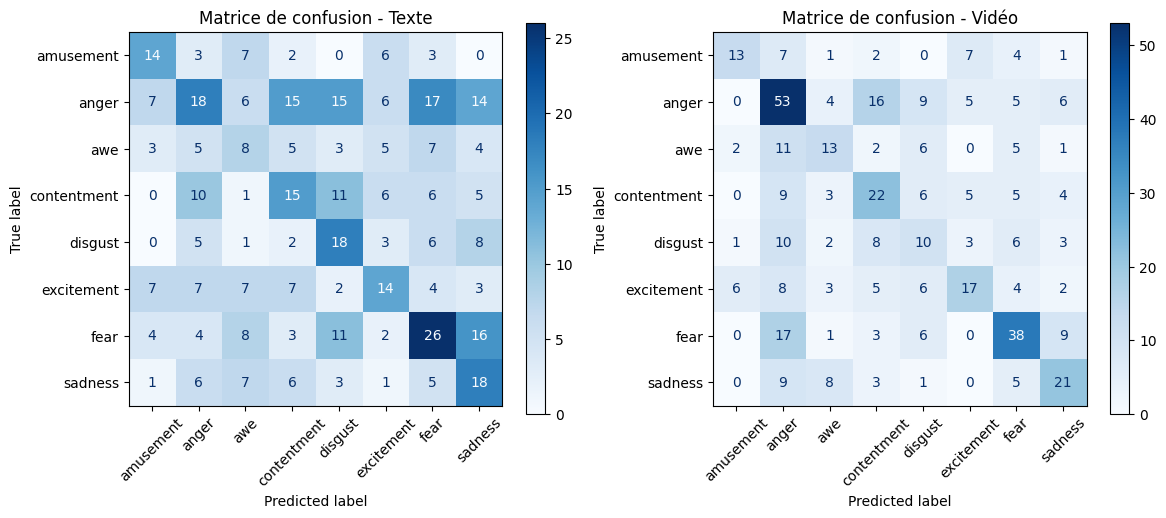

In [181]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matrice de confusion Texte
ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_dev,
    predictions_texte_dev,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[0]
)
axes[0].set_title("Matrice de confusion - Texte")

# Matrice de confusion Vidéo
ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_dev,
    predictions_video_dev,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[1]
)
axes[1].set_title("Matrice de confusion - Vidéo")

plt.tight_layout()
plt.show()

Marice de confusion sur Test

In [182]:
from sklearn.metrics import accuracy_score, f1_score, log_loss

# Prédictions Texte et Vidéo sur Test
predictions_texte_test = np.array(classes_emotions)[
    np.argmax(probabilites_texte_test, axis=1)
]

predictions_video_test = np.array(classes_emotions)[
    np.argmax(probabilites_video_test, axis=1)
]

# Évaluation du modèle Texte
print("MODÈLE TEXTE - TEST")
print("Accuracy :", accuracy_score(emotions_reelles_test, predictions_texte_test))
print("F1-score macro :", f1_score(
    emotions_reelles_test, predictions_texte_test, average="macro"
))
print("Log Loss :", log_loss(
    emotions_reelles_test, probabilites_texte_test, labels=classes_emotions
))

# Évaluation du modèle Vidéo
print("\nMODÈLE VIDÉO - TEST")
print("Accuracy :", accuracy_score(emotions_reelles_test, predictions_video_test))
print("F1-score macro :", f1_score(
    emotions_reelles_test, predictions_video_test, average="macro"
))
print("Log Loss :", log_loss(
    emotions_reelles_test, probabilites_video_test, labels=classes_emotions
))

MODÈLE TEXTE - TEST
Accuracy : 0.31890660592255127
F1-score macro : 0.3051123748111183
Log Loss : 1.8388116839095157

MODÈLE VIDÉO - TEST
Accuracy : 0.39863325740318906
F1-score macro : 0.35111824700283173
Log Loss : 1.689184238753715


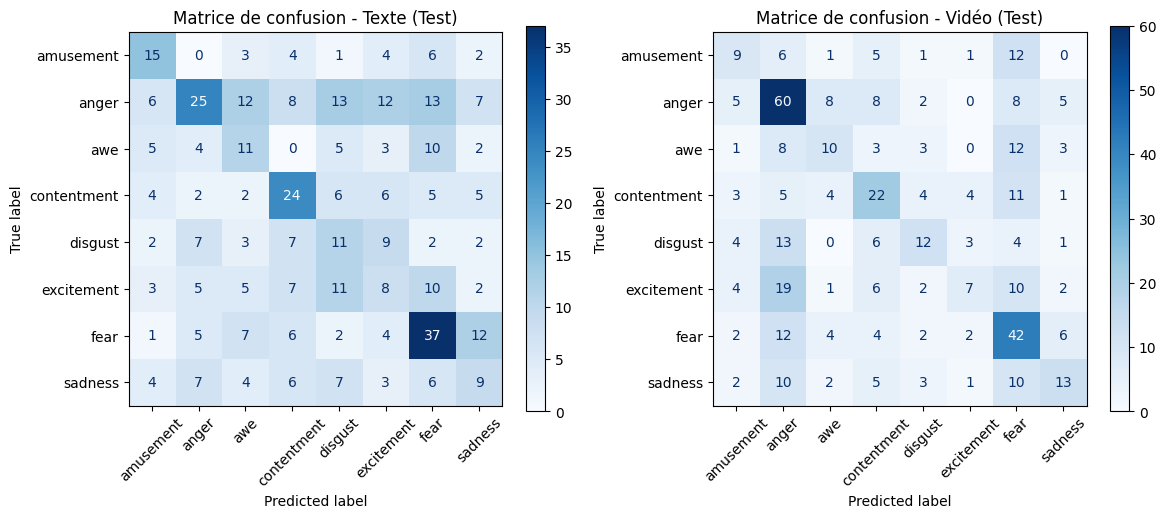

In [190]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matrice de confusion Texte - Test
ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_test,
    predictions_texte_test,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[0]
)
axes[0].set_title("Matrice de confusion - Texte (Test)")

# Matrice de confusion Vidéo - Test
ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_test,
    predictions_video_test,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[1]
)
axes[1].set_title("Matrice de confusion - Vidéo (Test)")

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

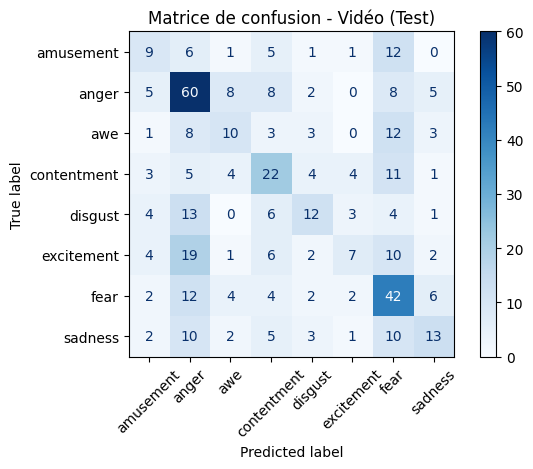

In [191]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_test,
    predictions_video_test,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Matrice de confusion - Vidéo (Test)")
plt.tight_layout()
plt.show()

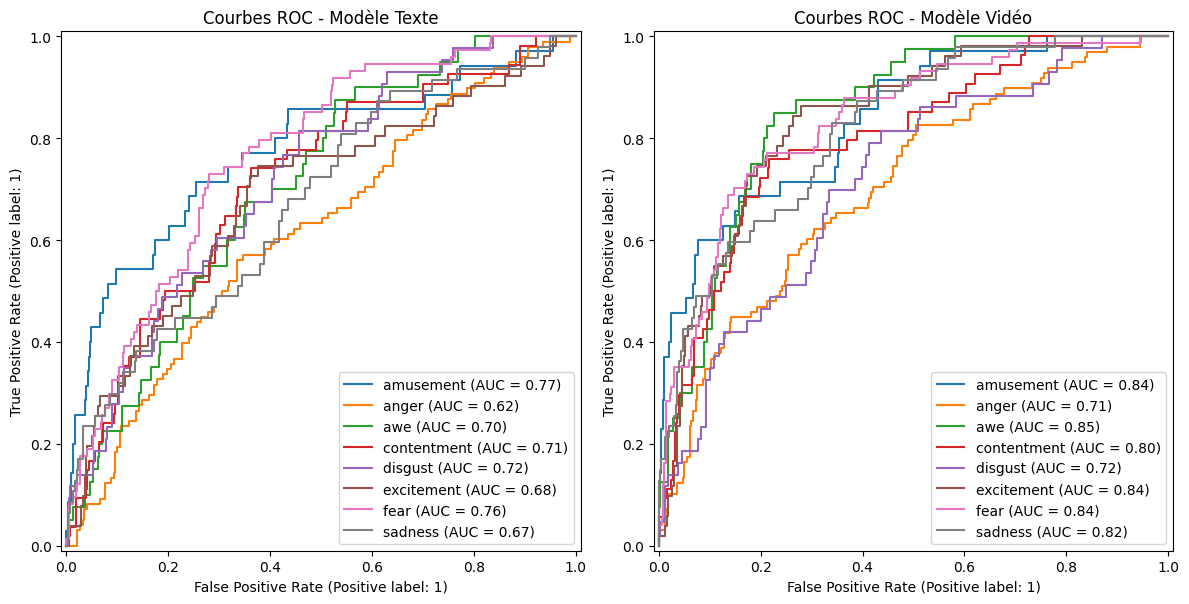

In [184]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import RocCurveDisplay

emotions_binaires_dev = label_binarize(
    emotions_reelles_dev,
    classes=classes_emotions
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for indice, emotion in enumerate(classes_emotions):
    RocCurveDisplay.from_predictions(
        emotions_binaires_dev[:, indice],
        probabilites_texte_dev[:, indice],
        name=emotion,
        ax=axes[0]
    )

axes[0].set_title("Courbes ROC - Modèle Texte")

# Courbes ROC - Vidéo
for indice, emotion in enumerate(classes_emotions):
    RocCurveDisplay.from_predictions(
        emotions_binaires_dev[:, indice],
        probabilites_video_dev[:, indice],
        name=emotion,
        ax=axes[1]
    )

axes[1].set_title("Courbes ROC - Modèle Vidéo")

plt.tight_layout()
plt.show()

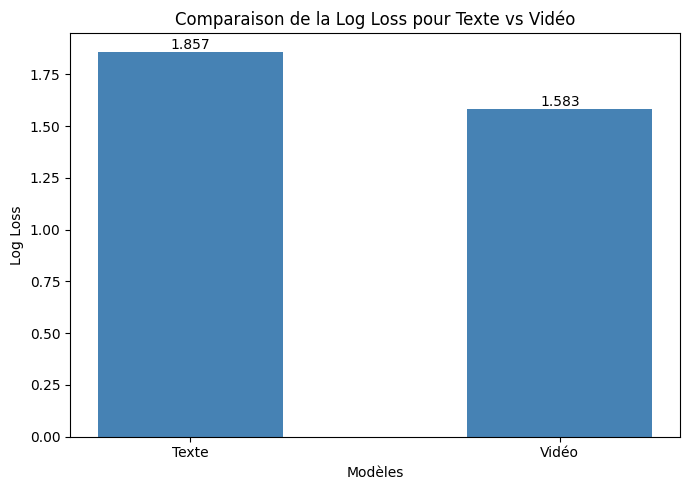

In [185]:
import matplotlib.pyplot as plt

noms_modeles = ["Texte", "Vidéo"]
valeurs_log_loss = [
    log_loss(emotions_reelles_dev, probabilites_texte_dev,
             labels=classes_emotions),
    log_loss(emotions_reelles_dev, probabilites_video_dev,
             labels=classes_emotions)
]

plt.figure(figsize=(7, 5))

barres = plt.bar(
    noms_modeles,
    valeurs_log_loss,
    color="steelblue",
    width=0.5
)

plt.title("Comparaison de la Log Loss pour Texte vs Vidéo")
plt.ylabel("Log Loss")
plt.xlabel("Modèles")

for barre in barres:
    plt.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height(),
        f"{barre.get_height():.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## Fusion tardive par moyenne des probabilités

In [45]:
probabilites_fusion_moyenne_dev = (probabilites_texte_dev + probabilites_video_dev) / 2
predictions_fusion_moyenne_dev = np.array(classes_emotions)[np.argmax(probabilites_fusion_moyenne_dev, axis=1)]
probabilites_fusion_moyenne_train = (
    probabilites_texte_train + probabilites_video_train
) / 2

predictions_fusion_moyenne_train = np.array(classes_emotions)[
    np.argmax(probabilites_fusion_moyenne_train, axis=1)
]
print("Dimensions :", probabilites_fusion_moyenne_dev.shape)
print("Nombre de prédictions :", len(predictions_fusion_moyenne_dev))


Dimensions : (442, 8)
Nombre de prédictions : 442


evaluer la fusion par moyenne

In [46]:
# Évaluation de la fusion par moyenne
print("FUSION TEXTE + VIDÉO (MOYENNE)")
print("Accuracy :", accuracy_score(emotions_reelles_dev,predictions_fusion_moyenne_dev))
print("F1-score macro :", f1_score(emotions_reelles_dev,predictions_fusion_moyenne_dev,average="macro"))
print("Log Loss :", log_loss(emotions_reelles_dev,probabilites_fusion_moyenne_dev,labels=classes_emotions))

FUSION TEXTE + VIDÉO (MOYENNE)
Accuracy : 0.4230769230769231
F1-score macro : 0.4192879494201977
Log Loss : 1.656140969732836


In [162]:
print("FUSION TEXTE + VIDÉO (MOYENNE) - TRAIN")

accuracy_fusion_moyenne_train = accuracy_score(
    emotions_reelles_train,
    predictions_fusion_moyenne_train
)

f1_fusion_moyenne_train = f1_score(
    emotions_reelles_train,
    predictions_fusion_moyenne_train,
    average="macro"
)

print("Accuracy :", accuracy_fusion_moyenne_train)
print("F1-score macro :", f1_fusion_moyenne_train)

FUSION TEXTE + VIDÉO (MOYENNE) - TRAIN
Accuracy : 0.5817852288173991
F1-score macro : 0.5617469599989868


Matrice de confusion

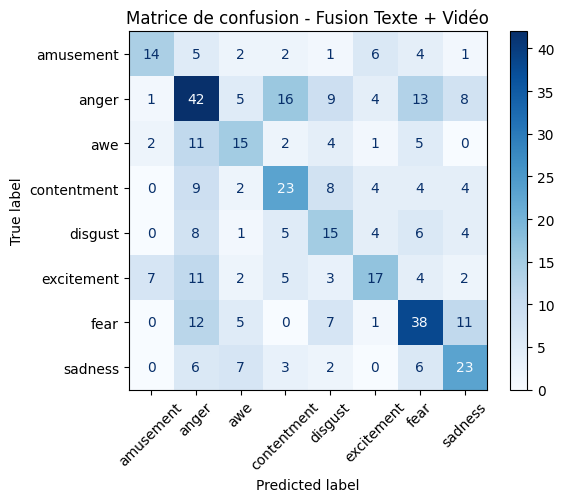

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_dev,
    predictions_fusion_moyenne_dev,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Matrice de confusion - Fusion Texte + Vidéo")

plt.tight_layout()
plt.show()

In [48]:
predictions_fusion_moyenne_train = np.array(classes_emotions)[
    np.argmax(probabilites_fusion_moyenne_train, axis=1)
]

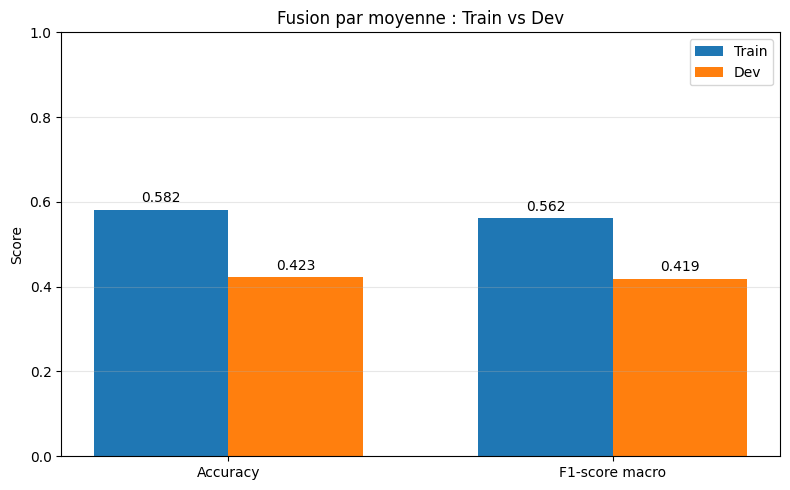

In [52]:
import numpy as np
import matplotlib.pyplot as plt

metriques = ["Accuracy", "F1-score macro"]
x = np.arange(len(metriques))
largeur = 0.35

plt.figure(figsize=(8, 5))
b1 = plt.bar(x - largeur/2, scores_train, largeur, label="Train")
b2 = plt.bar(x + largeur/2, scores_dev, largeur, label="Dev")

plt.bar_label(b1, fmt="%.3f", padding=3)
plt.bar_label(b2, fmt="%.3f", padding=3)

plt.xticks(x, metriques)
plt.ylabel("Score")
plt.title("Fusion par moyenne : Train vs Dev")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Comparaison des trois modèles

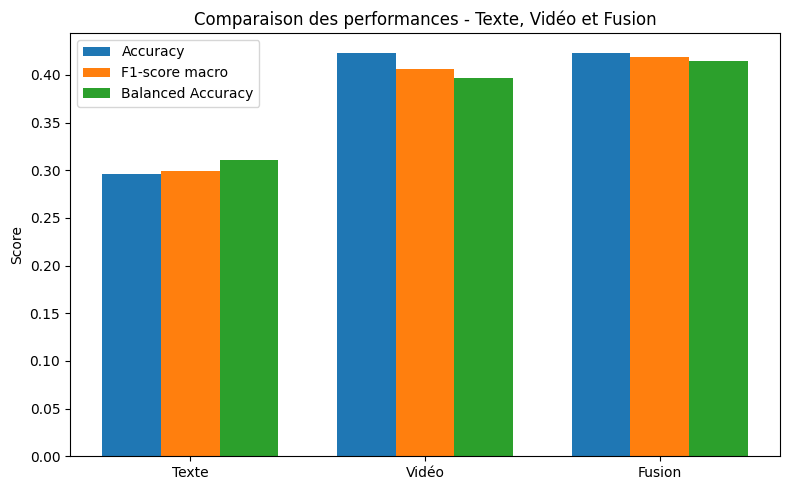

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score
noms_modeles = ["Texte", "Vidéo", "Fusion"]

valeurs_accuracy = [
    accuracy_score(emotions_reelles_dev, predictions_texte_dev),
    accuracy_score(emotions_reelles_dev, predictions_video_dev),
    accuracy_score(emotions_reelles_dev, predictions_fusion_moyenne_dev)
]

valeurs_f1 = [
    f1_score(emotions_reelles_dev, predictions_texte_dev, average="macro"),
    f1_score(emotions_reelles_dev, predictions_video_dev, average="macro"),
    f1_score(emotions_reelles_dev, predictions_fusion_moyenne_dev, average="macro")
]
valeurs_balanced_accuracy = [
    balanced_accuracy_score(emotions_reelles_dev, predictions_texte_dev),
    balanced_accuracy_score(emotions_reelles_dev, predictions_video_dev),
    balanced_accuracy_score(emotions_reelles_dev, predictions_fusion_moyenne_dev)
]

positions = np.arange(len(noms_modeles))
largeur = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

barres_accuracy = ax.bar(
    positions - largeur,
    valeurs_accuracy,
    largeur,
    label="Accuracy"
)

barres_f1 = ax.bar(
    positions,
    valeurs_f1,
    largeur,
    label="F1-score macro"
)

barres_balanced = ax.bar(
    positions + largeur,
    valeurs_balanced_accuracy,
    largeur,
    label="Balanced Accuracy"
)

ax.set_title("Comparaison des performances - Texte, Vidéo et Fusion")
ax.set_xticks(positions)
ax.set_xticklabels(noms_modeles)
ax.set_ylabel("Score")
ax.legend()

plt.tight_layout()
plt.show()

Comparaison de la Log Loss

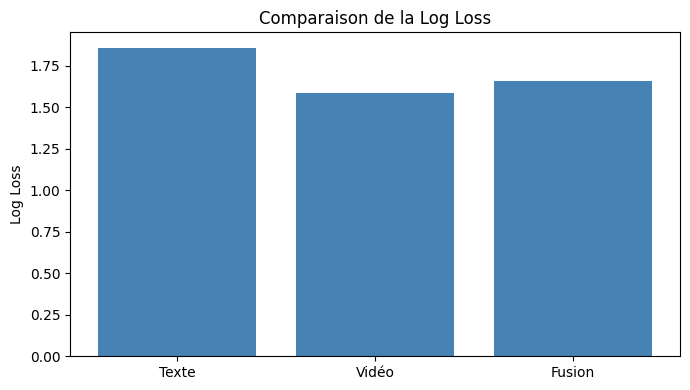

In [58]:
valeurs_log_loss = [
    log_loss(emotions_reelles_dev, probabilites_texte_dev, labels=classes_emotions),
    log_loss(emotions_reelles_dev, probabilites_video_dev, labels=classes_emotions),
    log_loss(emotions_reelles_dev, probabilites_fusion_moyenne_dev, labels=classes_emotions)
]

plt.figure(figsize=(7, 4))
plt.bar(noms_modeles, valeurs_log_loss, color="steelblue")

plt.title("Comparaison de la Log Loss")
plt.ylabel("Log Loss")
plt.tight_layout()
plt.show()

##Fusion tardive par moyenne ponderé des probabilités

In [59]:
poids_texte_testes = np.arange(0, 1.01, 0.05)

resultats_ponderation = []

for poids_texte in poids_texte_testes:

    poids_video = 1 - poids_texte
    probabilites_fusion = np.average(
        [probabilites_texte_dev, probabilites_video_dev],
        axis=0,
        weights=[poids_texte, poids_video]
    )

    #prédictions
    predictions_fusion = np.array(classes_emotions)[
        np.argmax(probabilites_fusion, axis=1)
    ]

    #Calcul du F1-score macro
    score_f1 = f1_score(
        emotions_reelles_dev,
        predictions_fusion,
        average="macro"
    )

    resultats_ponderation.append({
        "Poids Texte": poids_texte,
        "Poids Vidéo": poids_video,
        "F1-score macro": score_f1
    })

df_resultats_ponderation = pd.DataFrame(resultats_ponderation)
print(df_resultats_ponderation.to_string(index=False))

 Poids Texte  Poids Vidéo  F1-score macro
        0.00         1.00        0.405812
        0.05         0.95        0.407929
        0.10         0.90        0.411736
        0.15         0.85        0.409765
        0.20         0.80        0.408108
        0.25         0.75        0.409522
        0.30         0.70        0.417139
        0.35         0.65        0.416237
        0.40         0.60        0.414708
        0.45         0.55        0.409667
        0.50         0.50        0.419288
        0.55         0.45        0.413630
        0.60         0.40        0.413356
        0.65         0.35        0.412285
        0.70         0.30        0.397170
        0.75         0.25        0.387573
        0.80         0.20        0.363108
        0.85         0.15        0.343617
        0.90         0.10        0.332547
        0.95         0.05        0.312174
        1.00         0.00        0.298811


In [60]:
meilleur_resultat = df_resultats_ponderation.loc[df_resultats_ponderation["F1-score macro"].idxmax()]

meilleur_poids_texte = meilleur_resultat["Poids Texte"]
meilleur_poids_video = meilleur_resultat["Poids Vidéo"]

print("Meilleur poids Texte :", meilleur_poids_texte)
print("Meilleur poids Vidéo :", meilleur_poids_video)
print("Meilleur F1-score macro :", meilleur_resultat["F1-score macro"])

Meilleur poids Texte : 0.5
Meilleur poids Vidéo : 0.5
Meilleur F1-score macro : 0.4192879494201977


la moyenne pondérée n'apporte pas d'amélioration supplémentaire par rapport à la moyenne simple

## Fusion tardive par moyenen geometrique

In [115]:
epsilon = 1e-12

# log-probabilités
log_probas_texte = np.log(np.clip(probabilites_texte_dev, epsilon, 1))
log_probas_video = np.log(np.clip(probabilites_video_dev, epsilon, 1))

# Moyenne des log-probabilités
log_probas_fusion_geo = (log_probas_texte + log_probas_video) / 2

probabilites_fusion_geometrique_dev = np.exp(log_probas_fusion_geo)

# norrmalisation
probabilites_fusion_geometrique_dev = (
    probabilites_fusion_geometrique_dev /
    probabilites_fusion_geometrique_dev.sum(axis=1, keepdims=True)
)

# Prédictions finales
predictions_fusion_geometrique_dev = np.array(classes_emotions)[
    np.argmax(probabilites_fusion_geometrique_dev, axis=1)
]

print("Dimensions :", probabilites_fusion_geometrique_dev.shape)
print("Nombre de prédictions :", len(predictions_fusion_geometrique_dev))

Dimensions : (442, 8)
Nombre de prédictions : 442


Evaluation

In [116]:
print("FUSION GÉOMÉTRIQUE TEXTE + VIDÉO")
print("Accuracy :", accuracy_score(emotions_reelles_dev,predictions_fusion_geometrique_dev))
print("F1-score macro :", f1_score(emotions_reelles_dev,predictions_fusion_geometrique_dev,average="macro"))
print("Log Loss :", log_loss(emotions_reelles_dev,probabilites_fusion_geometrique_dev,labels=classes_emotions))

FUSION GÉOMÉTRIQUE TEXTE + VIDÉO
Accuracy : 0.42081447963800905
F1-score macro : 0.4167410012336523
Log Loss : 1.64435781057723


In [163]:
epsilon = 1e-12

log_probas_texte_train = np.log(
    np.clip(probabilites_texte_train, epsilon, 1)
)

log_probas_video_train = np.log(
    np.clip(probabilites_video_train, epsilon, 1)
)

log_probas_fusion_geo_train = (
    log_probas_texte_train + log_probas_video_train
) / 2

probabilites_fusion_geometrique_train = np.exp(
    log_probas_fusion_geo_train
)

probabilites_fusion_geometrique_train = (
    probabilites_fusion_geometrique_train /
    probabilites_fusion_geometrique_train.sum(
        axis=1,
        keepdims=True
    )
)

predictions_fusion_geometrique_train = np.array(
    classes_emotions
)[
    np.argmax(
        probabilites_fusion_geometrique_train,
        axis=1
    )
]

print("FUSION GÉOMÉTRIQUE TRAIN")

print(
    "Accuracy :",
    accuracy_score(
        emotions_reelles_train,
        predictions_fusion_geometrique_train
    )
)

print(
    "F1-score macro :",
    f1_score(
        emotions_reelles_train,
        predictions_fusion_geometrique_train,
        average="macro"
    )
)


FUSION GÉOMÉTRIQUE TRAIN
Accuracy : 0.5609424558223833
F1-score macro : 0.5419712088654236


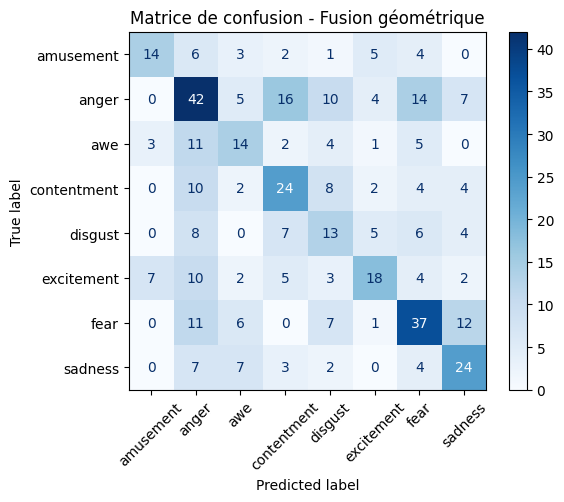

In [117]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    emotions_reelles_dev,
    predictions_fusion_geometrique_dev,
    labels=classes_emotions,
    display_labels=classes_emotions,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Matrice de confusion - Fusion géométrique")
plt.tight_layout()
plt.show()

In [118]:
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

accuracy_geo = accuracy_score(
    emotions_reelles_dev,
    predictions_fusion_geometrique_dev
)

f1_geo = f1_score(
    emotions_reelles_dev,
    predictions_fusion_geometrique_dev,
    average="macro"
)

balanced_accuracy_geo = balanced_accuracy_score(
    emotions_reelles_dev,
    predictions_fusion_geometrique_dev
)

print("Fusion géométrique - Dev")
print(f"Accuracy          : {accuracy_geo:.4f}")
print(f"F1-score macro    : {f1_geo:.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_geo:.4f}")

Fusion géométrique - Dev
Accuracy          : 0.4208
F1-score macro    : 0.4167
Balanced Accuracy : 0.4111


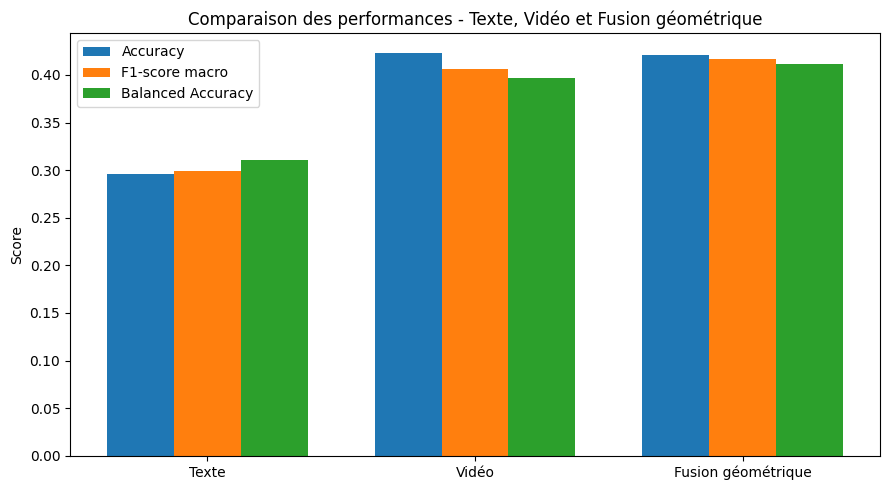

In [119]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

noms_modeles = ["Texte", "Vidéo", "Fusion géométrique"]

valeurs_accuracy = [
    accuracy_score(emotions_reelles_dev, predictions_texte_dev),
    accuracy_score(emotions_reelles_dev, predictions_video_dev),
    accuracy_score(emotions_reelles_dev, predictions_fusion_geometrique_dev)
]

valeurs_f1 = [
    f1_score(emotions_reelles_dev, predictions_texte_dev, average="macro"),
    f1_score(emotions_reelles_dev, predictions_video_dev, average="macro"),
    f1_score(emotions_reelles_dev, predictions_fusion_geometrique_dev, average="macro")
]

valeurs_balanced_accuracy = [
    balanced_accuracy_score(emotions_reelles_dev, predictions_texte_dev),
    balanced_accuracy_score(emotions_reelles_dev, predictions_video_dev),
    balanced_accuracy_score(emotions_reelles_dev, predictions_fusion_geometrique_dev)
]

positions = np.arange(len(noms_modeles))
largeur = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

barres_accuracy = ax.bar(
    positions - largeur,
    valeurs_accuracy,
    largeur,
    label="Accuracy"
)

barres_f1 = ax.bar(
    positions,
    valeurs_f1,
    largeur,
    label="F1-score macro"
)

barres_balanced = ax.bar(
    positions + largeur,
    valeurs_balanced_accuracy,
    largeur,
    label="Balanced Accuracy"
)

ax.set_title("Comparaison des performances - Texte, Vidéo et Fusion géométrique")
ax.set_xticks(positions)
ax.set_xticklabels(noms_modeles)
ax.set_ylabel("Score")
ax.legend()

plt.tight_layout()
plt.show()

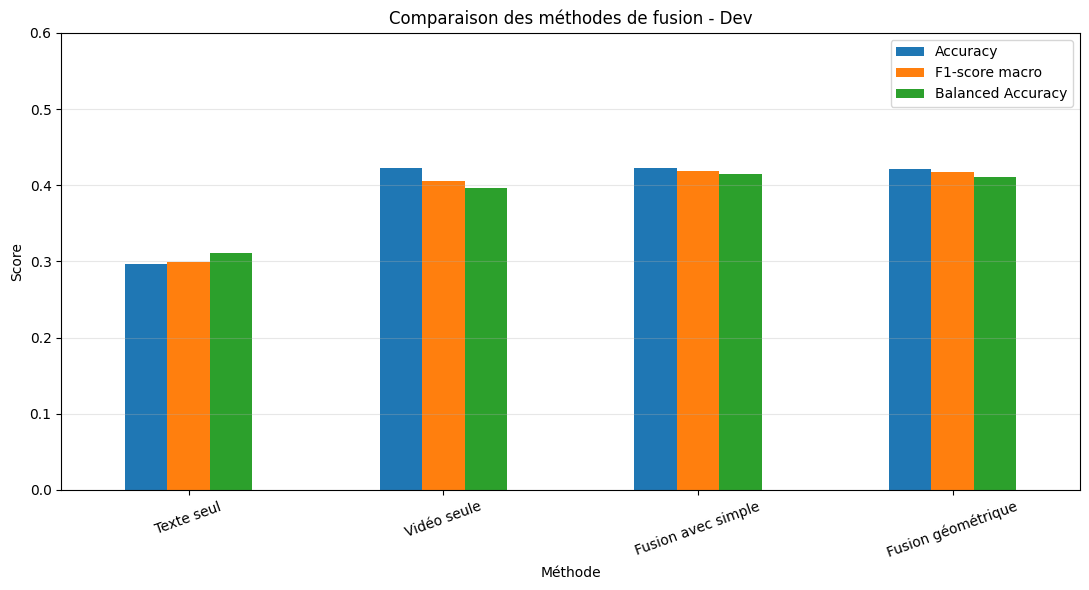

In [120]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

resultats_comparaison = pd.DataFrame({
    "Méthode": [
        "Texte seul",
        "Vidéo seule",
        "Fusion avec simple",
        "Fusion géométrique"
    ],
    "Accuracy": [
        0.2964,
        0.4231,
        0.4231,
        0.4208
    ],
    "F1-score macro": [
        0.2988,
        0.4058,
        0.4193,
        0.4167
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(emotions_reelles_dev, predictions_texte_dev),
        balanced_accuracy_score(emotions_reelles_dev, predictions_video_dev),
        balanced_accuracy_score(emotions_reelles_dev, predictions_fusion_moyenne_dev),
        balanced_accuracy_score(emotions_reelles_dev, predictions_fusion_geometrique_dev)
    ]
})

resultats_comparaison.plot(
    x="Méthode",
    y=["Accuracy", "F1-score macro", "Balanced Accuracy"],
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 0.6)
)

plt.title("Comparaison des méthodes de fusion - Dev")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

La modalité texte seule présente les performances les plus faibles (environ 0,30 de F1-macro), tandis que la vidéo seule atteint déjà de bonnes performances (≈0,40). Les méthodes de fusion apportent un léger gain supplémentaire, la fusion simple obtenant les meilleurs résultats globaux avec un F1-macro d'environ 0,42 et une Balanced Accuracy d'environ 0,41

# Fusion precoce

les deux fichiers d'embeddings Texte

In [121]:
import numpy as np

fichiers = [
    "embeddings_transcription.npz",
    "text_embeddings_caption.npz"
]

for nom in fichiers:
    chemin = ds_fusion_texte_video / nom
    data = np.load(chemin)

    print(f"\n{nom} ")
    print("Clés :", data.files)

    for cle in data.files:
        print(f"{cle} : {data[cle].shape}")


embeddings_transcription.npz 
Clés : ['video_id', 'X', 'available']
video_id : (3088,)
X : (3088, 384)
available : (3088,)

text_embeddings_caption.npz 
Clés : ['video_id', 'X', 'available']
video_id : (3088,)
X : (3088, 384)
available : (3088,)


In [122]:
X_video = np.load(ds_fusion_texte_video / "X_video_512.npy")

print("Dimensions des embeddings Vidéo :", X_video.shape)

Dimensions des embeddings Vidéo : (3088, 512)


Vérifier les identifiants et les partitions

In [123]:
import pandas as pd

df_partitions = pd.read_csv(ds_fusion_texte_video / "labels_partitions.csv")

print("Dimensions du fichier :", df_partitions.shape)
print("\nColonnes :")
print(df_partitions.columns.tolist())

print("\nPremières lignes :")
display(df_partitions.head())

Dimensions du fichier : (3088, 4)

Colonnes :
['video_id', 'emotion', 'split', 'film_id']

Premières lignes :


,video_id,emotion,split,film_id
0,00000_clip_001,anger,test,0
1,00000_clip_002,anger,test,0
2,00000_clip_006,contentment,test,0
3,00000_clip_009,anger,test,0
4,00000_clip_012,anger,test,0


Vérifier l'alignement des embeddings Texte

In [124]:
# Charger les embeddings Texte
emb_transcriptions = np.load(ds_fusion_texte_video / "embeddings_transcription.npz")
emb_captions = np.load(ds_fusion_texte_video / "text_embeddings_caption.npz")

ids_transcriptions = emb_transcriptions["video_id"]
ids_captions = emb_captions["video_id"]
ids_videos = df_partitions["video_id"].values

print("Nombre d'identifiants :")
print("Transcriptions :", len(ids_transcriptions))
print("Captions       :", len(ids_captions))
print("Partitions     :", len(ids_videos))

print("\nVérification des identifiants :")
print("Transcriptions = Partitions :", np.array_equal(ids_transcriptions, ids_videos))
print("Captions = Partitions       :", np.array_equal(ids_captions, ids_videos))
print("Transcriptions = Captions   :", np.array_equal(ids_transcriptions, ids_captions))

print("\nDisponibilité des embeddings :")
print("Transcriptions :", emb_transcriptions["available"].sum())
print("Captions       :", emb_captions["available"].sum())

Nombre d'identifiants :
Transcriptions : 3088
Captions       : 3088
Partitions     : 3088

Vérification des identifiants :
Transcriptions = Partitions : True
Captions = Partitions       : True
Transcriptions = Captions   : True

Disponibilité des embeddings :
Transcriptions : 2417
Captions       : 3088


In [125]:
df_partitions["transcription_disponible"] = emb_transcriptions["available"]

print(
    df_partitions.groupby("split")["transcription_disponible"]
    .agg(["count", "sum"])
)

       count   sum
split             
dev      442   340
test     439   333
train   2207  1744


la fusion précoce Captions + Vidéo

In [126]:
X_captions = emb_captions["X"]
X_video = np.load(ds_fusion_texte_video / "X_video_512.npy")

print("Dimensions des embeddings :")
print("Captions :", X_captions.shape)
print("Vidéo    :", X_video.shape)

print("\nNombre de valeurs manquantes :")
print("Captions :", np.isnan(X_captions).sum())
print("Vidéo    :", np.isnan(X_video).sum())

Dimensions des embeddings :
Captions : (3088, 384)
Vidéo    : (3088, 512)

Nombre de valeurs manquantes :
Captions : 0
Vidéo    : 0


Vérifier les partitions et les labels

In [127]:
y = df_partitions["emotion"].values
partitions = df_partitions["split"].values

print("Nombre d'extraits par partition :")
print(df_partitions["split"].value_counts())
print("\nNombre de classes :", df_partitions["emotion"].nunique())
print("\nClasses :", sorted(df_partitions["emotion"].unique()))
print("\nDimensions des labels :", y.shape)

Nombre d'extraits par partition :
split
train    2207
dev       442
test      439
Name: count, dtype: int64

Nombre de classes : 8

Classes : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']

Dimensions des labels : (3088,)


concaténer les deux embeddings.

In [128]:
# Fusion précoce : concaténation des embeddings
X_fusion = np.concatenate((X_captions, X_video), axis=1)

print("Dimensions des embeddings texte :", X_captions.shape)
print("Dimensions des embeddings vidéo :", X_video.shape)
print("Dimensions après fusion :", X_fusion.shape)

Dimensions des embeddings texte : (3088, 384)
Dimensions des embeddings vidéo : (3088, 512)
Dimensions après fusion : (3088, 896)


In [129]:
from sklearn.preprocessing import StandardScaler

# Séparation des données
embeddings_train = X_fusion[partitions == "train"]
embeddings_dev = X_fusion[partitions == "dev"]
embeddings_test = X_fusion[partitions == "test"]

labels_train = y[partitions == "train"]
labels_dev = y[partitions == "dev"]
labels_test = y[partitions == "test"]

# Standardisation
standardiseur = StandardScaler()
embeddings_train_norm = standardiseur.fit_transform(embeddings_train)
embeddings_dev_norm = standardiseur.transform(embeddings_dev)
embeddings_test_norm = standardiseur.transform(embeddings_test)

print("Train :", embeddings_train_norm.shape)
print("Dev   :", embeddings_dev_norm.shape)
print("Test  :", embeddings_test_norm.shape)

Train : (2207, 896)
Dev   : (442, 896)
Test  : (439, 896)


calssifieur regression logistique :

In [130]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

modele_fusion_precoce = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Entraînement
modele_fusion_precoce.fit(embeddings_train_norm, labels_train)

# Prédictions sur Dev
predictions_fusion_dev = modele_fusion_precoce.predict(embeddings_dev_norm)

# Évaluation
accuracy_fusion_dev = accuracy_score(labels_dev, predictions_fusion_dev)
balanced_accuracy_fusion_dev = balanced_accuracy_score(labels_dev, predictions_fusion_dev)
f1_macro_fusion_dev = f1_score(labels_dev, predictions_fusion_dev, average="macro")

print("Accuracy Dev :", accuracy_fusion_dev)
print("Balanced Accuracy Dev :", balanced_accuracy_fusion_dev)
print("F1-score macro Dev :", f1_macro_fusion_dev)

Accuracy Dev : 0.3393665158371041
Balanced Accuracy Dev : 0.35154268783961634
F1-score macro Dev : 0.3462018725301283


GMU

In [131]:
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import LabelEncoder

# Encodage des 8 émotions en nombres
encodeur_emotions = LabelEncoder()

labels_train_num = encodeur_emotions.fit_transform(labels_train)
labels_dev_num = encodeur_emotions.transform(labels_dev)
labels_test_num = encodeur_emotions.transform(labels_test)

appareil = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Appareil utilisé :", appareil)
print("Nombre de classes :", len(encodeur_emotions.classes_))
print("Classes :", encodeur_emotions.classes_)
print("Train :", embeddings_train_norm.shape)
print("Dev :", embeddings_dev_norm.shape)

Appareil utilisé : cpu
Nombre de classes : 8
Classes : ['amusement' 'anger' 'awe' 'contentment' 'disgust' 'excitement' 'fear'
 'sadness']
Train : (2207, 896)
Dev : (442, 896)


Séparation des deux modalités après standardisation


In [132]:
embeddings_texte_train = embeddings_train_norm[:, :384]
embeddings_video_train = embeddings_train_norm[:, 384:]
embeddings_texte_dev = embeddings_dev_norm[:, :384]
embeddings_video_dev = embeddings_dev_norm[:, 384:]
print("Texte Train :", embeddings_texte_train.shape)
print("Vidéo Train :", embeddings_video_train.shape)
print("Texte Dev :", embeddings_texte_dev.shape)
print("Vidéo Dev :", embeddings_video_dev.shape)

Texte Train : (2207, 384)
Vidéo Train : (2207, 512)
Texte Dev : (442, 384)
Vidéo Dev : (442, 512)


Construire l'architecture GMU

In [133]:
class GMU(nn.Module):
    def __init__(self, dimension_texte=384, dimension_video=512,
                 dimension_cachee=128, nombre_classes=8):

        super(GMU, self).__init__()

        # Transformation des embeddings texte
        self.projection_texte = nn.Linear(dimension_texte, dimension_cachee)

        # Transformation des embeddings vidéo
        self.projection_video = nn.Linear(dimension_video, dimension_cachee)

        # Porte de fusion
        self.porte = nn.Linear(2 * dimension_cachee, dimension_cachee)

        # Classification des émotions
        self.classifieur = nn.Linear(dimension_cachee, nombre_classes)

    def forward(self, texte, video):

        representation_texte = torch.tanh(self.projection_texte(texte))
        representation_video = torch.tanh(self.projection_video(video))

        # Calcul de la porte de fusion
        porte = torch.sigmoid(
            self.porte(torch.cat((texte_projection if False else representation_texte,
                                  representation_video), dim=1))
        )

        # Fusion des deux modalités
        representation_fusion = (
            porte * representation_texte
            + (1 - porte) * representation_video
        )

        # Prédiction des 8 émotions
        sortie = self.classifieur(representation_fusion)

        return sortie

Conversion des embeddings en tenseurs PyTorch


In [134]:
texte_train_tensor = torch.tensor(embeddings_texte_train, dtype=torch.float32)
video_train_tensor = torch.tensor(embeddings_video_train, dtype=torch.float32)
labels_train_tensor = torch.tensor(labels_train_num, dtype=torch.long)

texte_dev_tensor = torch.tensor(embeddings_texte_dev, dtype=torch.float32)
video_dev_tensor = torch.tensor(embeddings_video_dev, dtype=torch.float32)
labels_dev_tensor = torch.tensor(labels_dev_num, dtype=torch.long)

print("Texte Train :", texte_train_tensor.shape)
print("Vidéo Train :", video_train_tensor.shape)
print("Labels Train :", labels_train_tensor.shape)

print("Texte Dev :", texte_dev_tensor.shape)
print("Vidéo Dev :", video_dev_tensor.shape)
print("Labels Dev :", labels_dev_tensor.shape)

Texte Train : torch.Size([2207, 384])
Vidéo Train : torch.Size([2207, 512])
Labels Train : torch.Size([2207])
Texte Dev : torch.Size([442, 384])
Vidéo Dev : torch.Size([442, 512])
Labels Dev : torch.Size([442])


entraîner le GMU pour video avec captions

In [135]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
import copy

# Reproductibilité
torch.manual_seed(42)

# Préparation des données d'entraînement
jeu_donnees_train = TensorDataset(
    texte_train_tensor,
    video_train_tensor,
    labels_train_tensor
)

chargeur_donnees_train = DataLoader(
    jeu_donnees_train,
    batch_size=64,
    shuffle=True
)

# Calcul des poids des classes
poids_emotions = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels_train_num),
    y=labels_train_num
)

poids_emotions_tensor = torch.tensor(
    poids_emotions,
    dtype=torch.float32
)

# Initialisation du modèle
modele_gmu = GMU(
    dimension_texte=384,
    dimension_video=512,
    dimension_cachee=128,
    nombre_classes=8
).to(appareil)

# Fonction de perte et optimiseur
fonction_perte = nn.CrossEntropyLoss(
    weight=poids_emotions_tensor.to(appareil)
)

optimiseur = optim.AdamW(
    modele_gmu.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Modèle GMU prêt pour l'entraînement.")
print("Nombre de paramètres :", sum(p.numel() for p in modele_gmu.parameters()))

Modèle GMU prêt pour l'entraînement.
Nombre de paramètres : 148872


In [136]:
nombre_epoques = 100
patience = 15

meilleure_perte_dev = float("inf")
meilleur_modele_gmu = copy.deepcopy(modele_gmu.state_dict())
epoques_sans_amelioration = 0

historique_train = []
historique_dev = []

for epoque in range(nombre_epoques):

    # Entraînement
    modele_gmu.train()
    perte_train_totale = 0

    for texte_lot, video_lot, labels_lot in chargeur_donnees_train:

        texte_lot = texte_lot.to(appareil)
        video_lot = video_lot.to(appareil)
        labels_lot = labels_lot.to(appareil)

        optimiseur.zero_grad()

        sorties = modele_gmu(texte_lot, video_lot)
        perte = fonction_perte(sorties, labels_lot)

        perte.backward()
        optimiseur.step()

        perte_train_totale += perte.item() * len(labels_lot)

    perte_train_moyenne = perte_train_totale / len(jeu_donnees_train)

    # Validation
    modele_gmu.eval()

    with torch.no_grad():
        sorties_dev = modele_gmu(
            texte_dev_tensor.to(appareil),
            video_dev_tensor.to(appareil)
        )

        perte_dev = fonction_perte(
            sorties_dev,
            labels_dev_tensor.to(appareil)
        ).item()

    historique_train.append(perte_train_moyenne)
    historique_dev.append(perte_dev)

    # Sauvegarde du meilleur modèle
    if perte_dev < meilleure_perte_dev:
        meilleure_perte_dev = perte_dev
        meilleur_modele_gmu = copy.deepcopy(modele_gmu.state_dict())
        epoques_sans_amelioration = 0
    else:
        epoques_sans_amelioration += 1

    if (epoque + 1) % 10 == 0:
        print(
            f"Époque {epoque + 1}/{nombre_epoques} | "
            f"Perte Train : {perte_train_moyenne:.4f} | "
            f"Perte Dev : {perte_dev:.4f}"
        )

    if epoques_sans_amelioration >= patience:
        print(f"\nArrêt anticipé à l'époque {epoque + 1}")
        break

# Récupération du meilleur modèle
modele_gmu.load_state_dict(meilleur_modele_gmu)

print("\nMeilleure perte Dev :", meilleure_perte_dev)

Époque 10/100 | Perte Train : 0.1896 | Perte Dev : 2.0691

Arrêt anticipé à l'époque 17

Meilleure perte Dev : 1.6314289569854736


In [137]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

# Prédictions sur Dev
modele_gmu.eval()

with torch.no_grad():
    sorties_gmu_dev = modele_gmu(
        texte_dev_tensor.to(appareil),
        video_dev_tensor.to(appareil)
    )

    predictions_gmu_dev = torch.argmax(
        sorties_gmu_dev, dim=1
    ).cpu().numpy()

# Évaluation
accuracy_gmu_dev = accuracy_score(labels_dev_num, predictions_gmu_dev)

balanced_accuracy_gmu_dev = balanced_accuracy_score(
    labels_dev_num, predictions_gmu_dev
)

f1_macro_gmu_dev = f1_score(
    labels_dev_num,
    predictions_gmu_dev,
    average="macro"
)

print("Accuracy GMU Dev :", accuracy_gmu_dev)
print("Balanced Accuracy GMU Dev :", balanced_accuracy_gmu_dev)
print("F1-score macro GMU Dev :", f1_macro_gmu_dev)

Accuracy GMU Dev : 0.3755656108597285
Balanced Accuracy GMU Dev : 0.3911610045530561
F1-score macro GMU Dev : 0.3732535858195302


In [164]:
print("Accuracy Train :", accuracy_gmu_train)
print("F1-score macro Train :", f1_macro_gmu_train)

Accuracy Train : 0.6357045763479837
F1-score macro Train : 0.6357841453709796


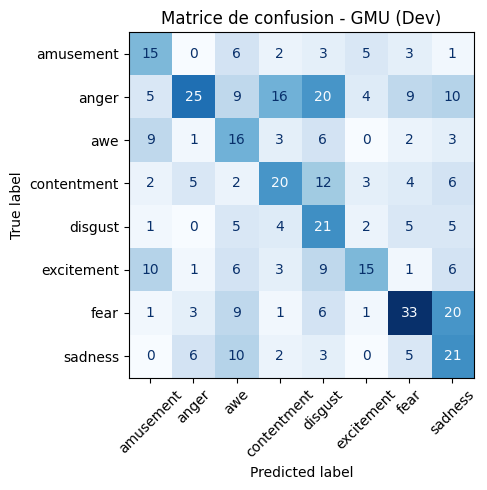

In [138]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_confusion_gmu = confusion_matrix(
    labels_dev_num,
    predictions_gmu_dev
)

affichage_matrice = ConfusionMatrixDisplay(
    confusion_matrix=matrice_confusion_gmu,
    display_labels=encodeur_emotions.classes_
)

fig, ax = plt.subplots(figsize=(7, 5))

affichage_matrice.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("Matrice de confusion - GMU (Dev)")
plt.tight_layout()
plt.show()

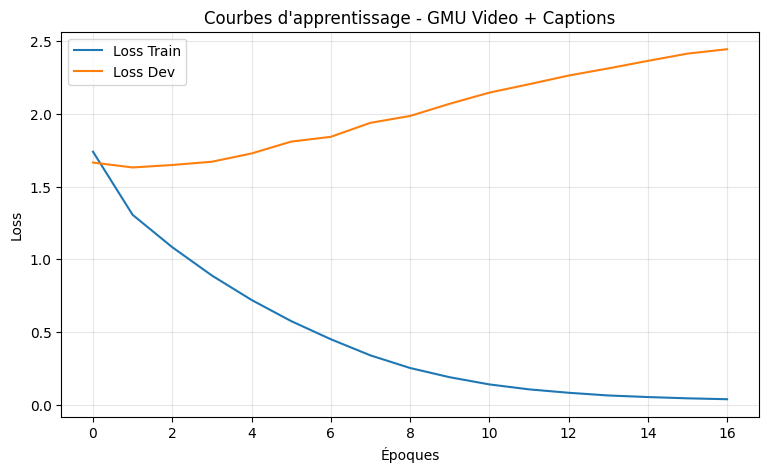

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(historique_train, label="Loss Train")
plt.plot(historique_dev, label="Loss Dev")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Courbes d'apprentissage - GMU Video + Captions")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [140]:
# Prédictions sur Train
modele_gmu.eval()

with torch.no_grad():
    sorties_gmu_train = modele_gmu(
        texte_train_tensor.to(appareil),
        video_train_tensor.to(appareil)
    )

    predictions_gmu_train = torch.argmax(
        sorties_gmu_train, dim=1
    ).cpu().numpy()

# Évaluation sur Train
accuracy_gmu_train = accuracy_score(
    labels_train_num, predictions_gmu_train
)

balanced_accuracy_gmu_train = balanced_accuracy_score(
    labels_train_num, predictions_gmu_train
)

f1_macro_gmu_train = f1_score(
    labels_train_num,
    predictions_gmu_train,
    average="macro"
)

print("Accuracy Train :", accuracy_gmu_train)
print("Balanced Accuracy Train :", balanced_accuracy_gmu_train)
print("F1-score macro Train :", f1_macro_gmu_train)

print("\n--- Résultats Dev ---")
print("Accuracy Dev :", accuracy_gmu_dev)
print("Balanced Accuracy Dev :", balanced_accuracy_gmu_dev)
print("F1-score macro Dev :", f1_macro_gmu_dev)

Accuracy Train : 0.6357045763479837
Balanced Accuracy Train : 0.657108995509575
F1-score macro Train : 0.6357841453709796

--- Résultats Dev ---
Accuracy Dev : 0.3755656108597285
Balanced Accuracy Dev : 0.3911610045530561
F1-score macro Dev : 0.3732535858195302


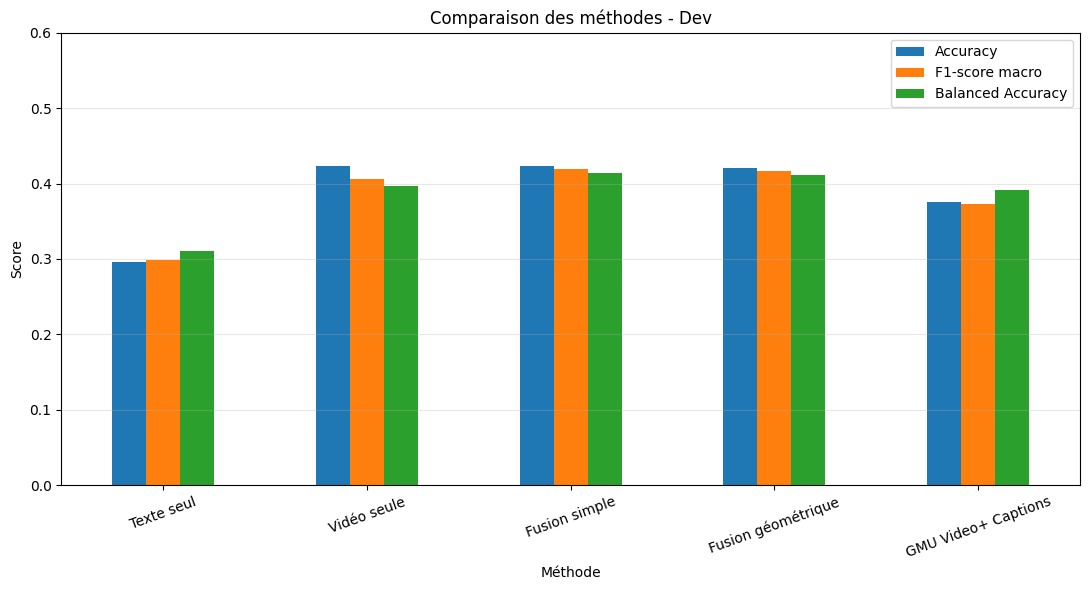

In [142]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

resultats_comparaison = pd.DataFrame({
    "Méthode": [
        "Texte seul",
        "Vidéo seule",
        "Fusion simple",
        "Fusion géométrique",
        "GMU Video+ Captions"
    ],
    "Accuracy": [
        0.2964,
        0.4231,
        0.4231,
        0.4208,
        accuracy_gmu_dev
    ],
    "F1-score macro": [
        0.2988,
        0.4058,
        0.4193,
        0.4167,
        f1_macro_gmu_dev
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(emotions_reelles_dev, predictions_texte_dev),
        balanced_accuracy_score(emotions_reelles_dev, predictions_video_dev),
        balanced_accuracy_score(emotions_reelles_dev, predictions_fusion_moyenne_dev),
        balanced_accuracy_score(emotions_reelles_dev, predictions_fusion_geometrique_dev),
        balanced_accuracy_gmu_dev
    ]
})

resultats_comparaison.plot(
    x="Méthode",
    y=["Accuracy", "F1-score macro", "Balanced Accuracy"],
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 0.6)
)

plt.title("Comparaison des méthodes - Dev")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

La Fusion simple obtient les meilleurs résultats sur l'ensemble Dev (Accuracy ≈ 0,42 ; F1-macro ≈ 0,42), suivie de près par la Fusion géométrique et la Vidéo seule. Le GMU reste moins performant, tandis que le Texte seul présente les scores les plus faibles. Ces résultats confirment l'intérêt des approches multimodales pour la reconnaissance des émotion

# Fusion  video Captions transcriptions

In [143]:
print(emb_transcriptions.files)

['video_id', 'X', 'available']


In [156]:
# Récupérer les données
ids_transcriptions = emb_transcriptions["video_id"]
X_transcriptions_disponibles = emb_transcriptions["X"]
masque_disponible = emb_transcriptions["available"]

print("Embeddings disponibles :", X_transcriptions_disponibles.shape)
print("Nombre de transcriptions disponibles :", masque_disponible.sum())

Embeddings disponibles : (3088, 384)
Nombre de transcriptions disponibles : 2417


 Remplacer par zéro les embeddings des transcriptions absentes

In [145]:
X_transcriptions = emb_transcriptions["X"].copy()
X_transcriptions[~emb_transcriptions["available"]] = 0
print("Dimensions :", X_transcriptions.shape)
print("Valeurs manquantes :", np.isnan(X_transcriptions).sum())

Dimensions : (3088, 384)
Valeurs manquantes : 0


In [146]:
X_disponibilite = emb_transcriptions["available"].astype(float).reshape(-1, 1)
print("Dimensions de l'indicateur :", X_disponibilite.shape)

Dimensions de l'indicateur : (3088, 1)


In [147]:
# Fusion des transcriptions, des captions et de la vidéo
X_fusion_transcriptions_captions_video = np.concatenate((X_transcriptions, X_captions, X_video),axis=1)
print("Dimensions de la fusion :", X_fusion_transcriptions_captions_video.shape)

Dimensions de la fusion : (3088, 1280)


separation des donnees

In [148]:
# Séparation des données
embeddings_train_transcriptions_captions_video = X_fusion_transcriptions_captions_video[partitions == "train"]
embeddings_dev_transcriptions_captions_video = X_fusion_transcriptions_captions_video[partitions == "dev"]
embeddings_test_transcriptions_captions_video = X_fusion_transcriptions_captions_video[partitions == "test"]

labels_train = y[partitions == "train"]
labels_dev = y[partitions == "dev"]
labels_test = y[partitions == "test"]

print("Train :", embeddings_train_transcriptions_captions_video.shape)
print("Dev :", embeddings_dev_transcriptions_captions_video.shape)
print("Test :", embeddings_test_transcriptions_captions_video.shape)

Train : (2207, 1280)
Dev : (442, 1280)
Test : (439, 1280)


normalise les embeddings

In [149]:
from sklearn.preprocessing import StandardScaler

standardiseur_transcriptions_captions_video = StandardScaler()

embeddings_train_transcriptions_captions_video_norm = standardiseur_transcriptions_captions_video.fit_transform(
    embeddings_train_transcriptions_captions_video
)

embeddings_dev_transcriptions_captions_video_norm = standardiseur_transcriptions_captions_video.transform(
    embeddings_dev_transcriptions_captions_video
)

embeddings_test_transcriptions_captions_video_norm = standardiseur_transcriptions_captions_video.transform(
    embeddings_test_transcriptions_captions_video
)

print("Train :", embeddings_train_transcriptions_captions_video_norm.shape)
print("Dev :", embeddings_dev_transcriptions_captions_video_norm.shape)
print("Test :", embeddings_test_transcriptions_captions_video_norm.shape)

Train : (2207, 1280)
Dev : (442, 1280)
Test : (439, 1280)


Regression logistqiue video transcription captions

In [150]:
modele_fusion_transcriptions_captions_video = LogisticRegression(
    C=0.002,
    solver="saga",
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

modele_fusion_transcriptions_captions_video.fit(
    embeddings_train_transcriptions_captions_video_norm,
    labels_train
)



LogisticRegression(C=0.002, class_weight='balanced', max_iter=2000,
                   random_state=42, solver='saga')

In [151]:
predictions_fusion_transcriptions_captions_video = modele_fusion_transcriptions_captions_video.predict(
    embeddings_dev_transcriptions_captions_video_norm
)

probabilites_fusion_transcriptions_captions_video = modele_fusion_transcriptions_captions_video.predict_proba(
    embeddings_dev_transcriptions_captions_video_norm
)

print("Dimensions des prédictions :", predictions_fusion_transcriptions_captions_video.shape)
print("Dimensions des probabilités :", probabilites_fusion_transcriptions_captions_video.shape)

Dimensions des prédictions : (442,)
Dimensions des probabilités : (442, 8)


In [158]:
predictions_fusion_transcriptions_captions_video_train = (
    modele_fusion_transcriptions_captions_video.predict(
        embeddings_train_transcriptions_captions_video_norm
    )
)

probabilites_fusion_transcriptions_captions_video_train = (
    modele_fusion_transcriptions_captions_video.predict_proba(
        embeddings_train_transcriptions_captions_video_norm
    )
)

In [152]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

accuracy_fusion_transcriptions_captions_video = accuracy_score(
    labels_dev,
    predictions_fusion_transcriptions_captions_video
)

balanced_accuracy_fusion_transcriptions_captions_video = balanced_accuracy_score(
    labels_dev,
    predictions_fusion_transcriptions_captions_video
)

f1_macro_fusion_transcriptions_captions_video = f1_score(
    labels_dev,
    predictions_fusion_transcriptions_captions_video,
    average="macro"
)

print("Accuracy :", accuracy_fusion_transcriptions_captions_video)
print("Balanced Accuracy :", balanced_accuracy_fusion_transcriptions_captions_video)
print("F1-score macro :", f1_macro_fusion_transcriptions_captions_video)

Accuracy : 0.39592760180995473
Balanced Accuracy : 0.414422030790524
F1-score macro : 0.40103000150994444


In [159]:

accuracy_train = accuracy_score(
    labels_train,
    predictions_fusion_transcriptions_captions_video_train
)

balanced_accuracy_train = balanced_accuracy_score(
    labels_train,
    predictions_fusion_transcriptions_captions_video_train
)

f1_train = f1_score(
    labels_train,
    predictions_fusion_transcriptions_captions_video_train,
    average="macro"
)

print("Accuracy Train :", accuracy_train)
print("Balanced Accuracy Train :", balanced_accuracy_train)
print("F1 Train :", f1_train)

Accuracy Train : 0.7698232895333031
Balanced Accuracy Train : 0.7912328925739379
F1 Train : 0.7745908990850172


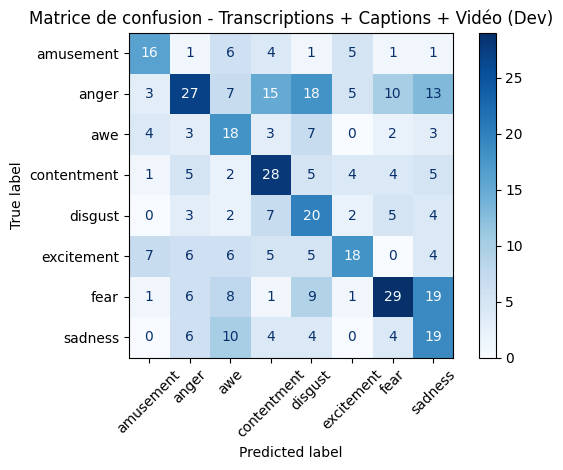

In [153]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matrice_confusion_transcriptions_captions_video = confusion_matrix(
    labels_dev,
    predictions_fusion_transcriptions_captions_video,
    labels=modele_fusion_transcriptions_captions_video.classes_
)

affichage_matrice_transcriptions_captions_video = ConfusionMatrixDisplay(
    confusion_matrix=matrice_confusion_transcriptions_captions_video,
    display_labels=modele_fusion_transcriptions_captions_video.classes_
)

affichage_matrice_transcriptions_captions_video.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Matrice de confusion - Transcriptions + Captions + Vidéo (Dev)")
plt.tight_layout()
plt.show()

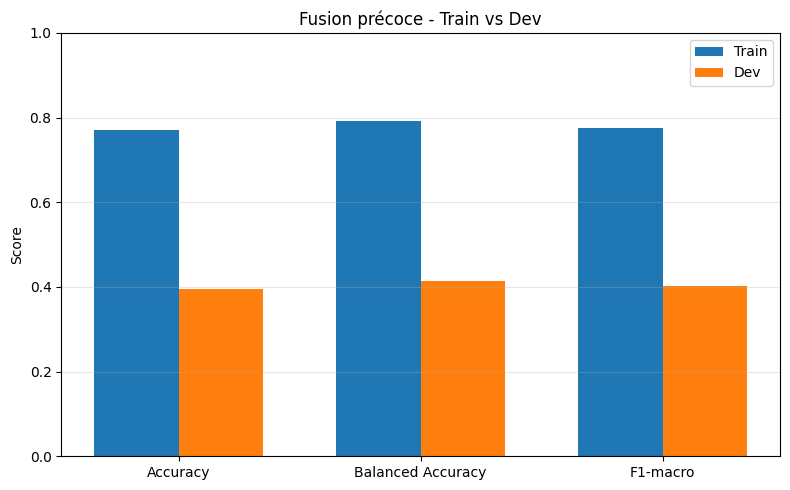

In [160]:
import matplotlib.pyplot as plt
import numpy as np

metriques = ["Accuracy", "Balanced Accuracy", "F1-macro"]

scores_train = [
    0.7698,
    0.7912,
    0.7746
]

scores_dev = [
    0.3959,
    0.4144,
    0.4010
]

x = np.arange(len(metriques))
largeur = 0.35

plt.figure(figsize=(8,5))

plt.bar(
    x - largeur/2,
    scores_train,
    largeur,
    label="Train"
)

plt.bar(
    x + largeur/2,
    scores_dev,
    largeur,
    label="Dev"
)

plt.xticks(x, metriques)
plt.ylabel("Score")
plt.title("Fusion précoce - Train vs Dev")
plt.legend()
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Comparaison la perfomances

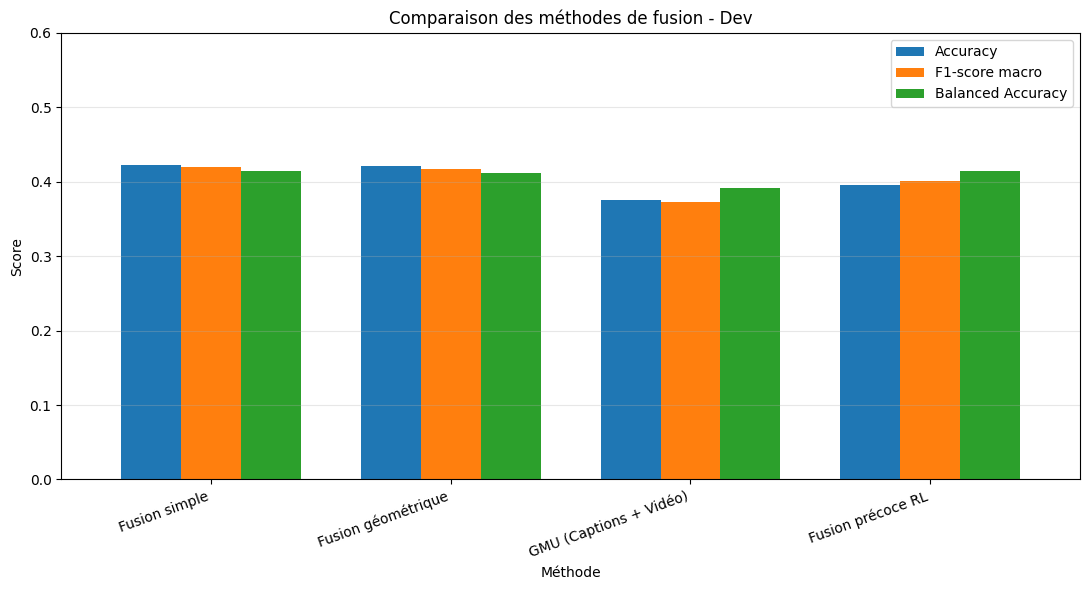

In [192]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

resultats_comparaison = pd.DataFrame({
    "Méthode": [
        "Fusion simple",
        "Fusion géométrique",
        "GMU (Captions + Vidéo)",
        "Fusion précoce RL"
    ],
    "Accuracy": [
        0.4231,
        0.4208,
        accuracy_gmu_dev,
        accuracy_fusion_transcriptions_captions_video
    ],
    "F1-score macro": [
        0.4193,
        0.4167,
        f1_macro_gmu_dev,
        f1_macro_fusion_transcriptions_captions_video
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(
            emotions_reelles_dev,
            predictions_fusion_moyenne_dev
        ),
        balanced_accuracy_score(
            emotions_reelles_dev,
            predictions_fusion_geometrique_dev
        ),
        balanced_accuracy_gmu_dev,
        balanced_accuracy_fusion_transcriptions_captions_video
    ]
})

resultats_comparaison.plot(
    x="Méthode",
    y=["Accuracy", "F1-score macro", "Balanced Accuracy"],
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 0.6),
    width=0.75
)

plt.title("Comparaison des méthodes de fusion - Dev")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

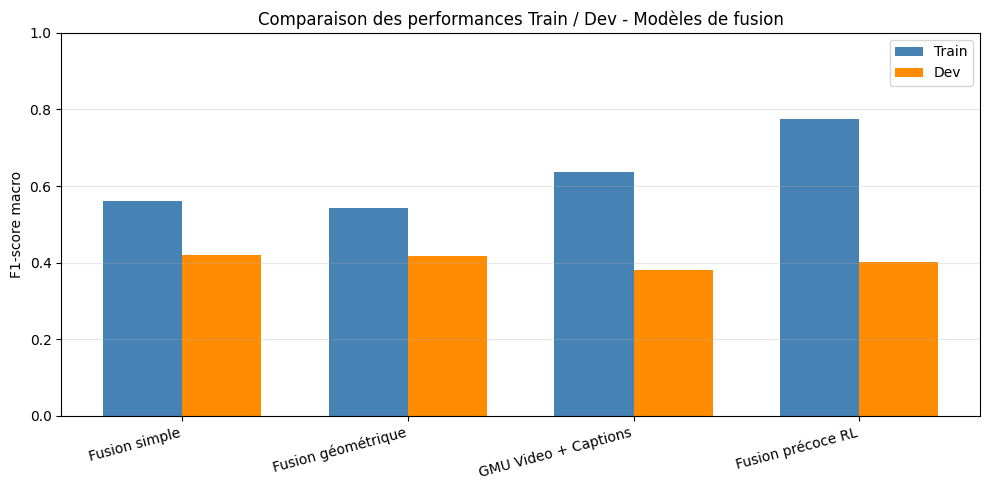

In [193]:
import matplotlib.pyplot as plt
import numpy as np

modeles = [
    "Fusion simple",
    "Fusion géométrique",
    "GMU Video + Captions",
    "Fusion précoce RL"
]

f1_train = [
    0.5617,
    0.5420,
    0.6358,
    0.7746
]

f1_dev = [
    0.4193,
    0.4167,
    0.3801,
    0.4010
]

x = np.arange(len(modeles))
largeur = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - largeur/2,
    f1_train,
    largeur,
    label="Train",
    color="steelblue"
)

plt.bar(
    x + largeur/2,
    f1_dev,
    largeur,
    label="Dev",
    color="darkorange"
)

plt.xticks(x, modeles, rotation=15, ha="right")
plt.ylabel("F1-score macro")
plt.title("Comparaison des performances Train / Dev - Modèles de fusion")
plt.ylim(0, 1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Évaluation de la fusion tardive

FUSION TARDIVE - TEST
Accuracy : 0.4054669703872437
Balanced Accuracy : 0.36183899020078614
F1-score macro : 0.35915762683289265


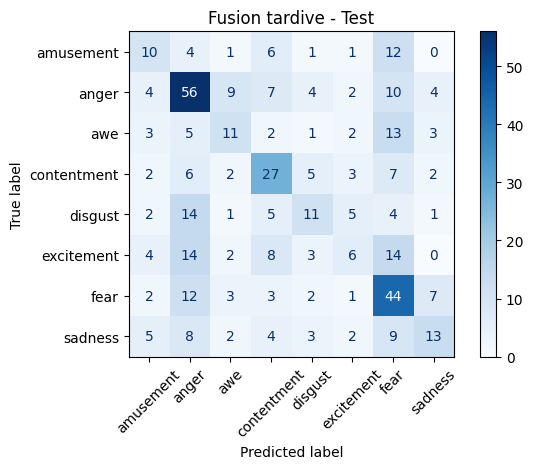

In [200]:
# Fusion tardive par moyenne simple
probabilites_fusion_moyenne_test = (
    probabilites_texte_test + probabilites_video_test
) / 2

# Prédictions
predictions_fusion_moyenne_test = np.array(classes_emotions)[
    np.argmax(probabilites_fusion_moyenne_test, axis=1)
]

# Évaluation
accuracy_fusion_tardive_test = accuracy_score(
    emotions_reelles_test,
    predictions_fusion_moyenne_test
)

balanced_accuracy_fusion_tardive_test = balanced_accuracy_score(
    emotions_reelles_test,
    predictions_fusion_moyenne_test
)

f1_macro_fusion_tardive_test = f1_score(
    emotions_reelles_test,
    predictions_fusion_moyenne_test,
    average="macro"
)

print("FUSION TARDIVE - TEST")
print("Accuracy :", accuracy_fusion_tardive_test)
print("Balanced Accuracy :", balanced_accuracy_fusion_tardive_test)
print("F1-score macro :", f1_macro_fusion_tardive_test)

# Matrice de confusion
matrice_tardive_test = confusion_matrix(
    emotions_reelles_test,
    predictions_fusion_moyenne_test,
    labels=classes_emotions
)

affichage_tardive_test = ConfusionMatrixDisplay(
    confusion_matrix=matrice_tardive_test,
    display_labels=classes_emotions
)

affichage_tardive_test.plot(cmap="Blues", xticks_rotation=45)
plt.title("Fusion tardive - Test")
plt.tight_layout()
plt.show()

In [201]:
# Sauvegarder les probabilités du modèle final de fusion tardive

df_probas_tardive = pd.DataFrame(
    probabilites_fusion_moyenne_test,
    columns=[f"proba_{emotion}" for emotion in classes_emotions]
)

df_probas_tardive.insert(0, "video_id", video_ids_test)

# Ajouter les émotions réelles et prédites
df_probas_tardive["emotion_reelle"] = emotions_reelles_test
df_probas_tardive["emotion_predite"] = predictions_fusion_moyenne_test

# Export CSV
df_probas_tardive.to_csv(
    "probabilites_fusion_tardive_test.csv",
    index=False
)

print("Fichier sauvegardé !")
print(df_probas_tardive.head())

Fichier sauvegardé !
         video_id  proba_amusement  proba_anger  proba_awe  proba_contentment  \
0  00000_clip_001         0.133454     0.318884   0.057109           0.152930   
1  00000_clip_002         0.130067     0.344638   0.077269           0.067286   
2  00000_clip_006         0.348471     0.208625   0.052599           0.087295   
3  00000_clip_009         0.089484     0.458857   0.031085           0.058927   
4  00000_clip_012         0.066524     0.469793   0.070427           0.082490   

   proba_disgust  proba_excitement  proba_fear  proba_sadness emotion_reelle  \
0       0.139943          0.090539    0.061957       0.045185          anger   
1       0.157087          0.108057    0.064839       0.050758          anger   
2       0.137924          0.092328    0.050012       0.022747    contentment   
3       0.097815          0.186589    0.031849       0.045394          anger   
4       0.119467          0.098071    0.041663       0.051566          anger   

  emotion_p